Task 1: Load the Dataset. In this step I load the Pima Indians Diabetes data straight from the internet into a Pandas table. The original file comes with no column names, so I added them myself to match the features in the assignment. Then I print the size of the table and the first few rows to make sure everything loaded correctly.

In [1]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
cols = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
        "insulin", "bmi", "diabetes_pedigree_function", "age", "outcome"]

df = pd.read_csv(url, header=None, names=cols)
print(df.shape)
df.head()

(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Task 2: Inspect the Data. In this step I look at the table in three ways. I’m looking for two things how the values are spread out, and any odd placeholder values. In this dataset, missing values aren’t left blank. A lot of them are filled in with a 0 instead, which pandas treats as a real number. So I’m checking the minimum of each column for zeros that don’t make sense.

In [2]:
df.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   pregnancies                 768 non-null    int64  
 1   glucose                     768 non-null    int64  
 2   blood_pressure              768 non-null    int64  
 3   skin_thickness              768 non-null    int64  
 4   insulin                     768 non-null    int64  
 5   bmi                         768 non-null    float64
 6   diabetes_pedigree_function  768 non-null    float64
 7   age                         768 non-null    int64  
 8   outcome                     768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Task 3: Missing Values. In this step I find the hidden missing values. info() said nothing was missing, but in this dataset a 0 is used as a placeholder when a measurement wasn’t taken. A glucose, blood pressure, skin thickness, insulin, or BMI of 0 isn’t possible for a living patient, so I count the zeros in those five columns and swap them for real blanks. I leave pregnancies alone, since 0 pregnancies is a real answer, and I leave outcome alone, since 0 means no diabetes. Then I plan to fill the blanks with the median, because a few extreme values, like very high insulin, would pull an average up and the median stays closer to a typical patient.

In [5]:
from sklearn.impute import SimpleImputer

zero_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]

print("Zeros before:")
print((df[zero_cols] == 0).sum())

df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("Missing after:")
print(df.isnull().sum())

Zeros before:
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64
Missing after:
pregnancies                     0
glucose                         5
blood_pressure                 35
skin_thickness                227
insulin                       374
bmi                            11
diabetes_pedigree_function      0
age                             0
outcome                         0
dtype: int64


Task 4: Build the Pipeline. In this step I split the data into a training set and a test set first, so the test data stays unseen until I grade the models. Then I build one automatic prep line with a ColumnTransformer. First the blanks get filled with the median using SimpleImputer, and then the values are scaled with StandardScaler so every column is on a similar size and no column wins just because its numbers are bigger. I put this inside a pipeline so the medians and scaling are learned from the training data only.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X = df.drop(columns="outcome")
y = df["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = list(X.columns)

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())])

preprocess = ColumnTransformer([("num", num_pipe, num_cols)])

print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


Task 5: Hard and Soft Voting Classifiers. In this step I combine three different models, Logistic Regression, a Support Vector Classifier, and a Decision Tree, into one team that votes on each patient. In the hard voting version, each model gives a yes or no answer and the answer with the most votes wins. I also train the three models on their own so I can see whether the team actually beats them.

Hard Voting test accuracy: 0.7403
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154

Soft Voting test accuracy: 0.7273
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       100
           1       0.64      0.52      0.57        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.69       154
weighted avg       0.72      0.73      0.72       154



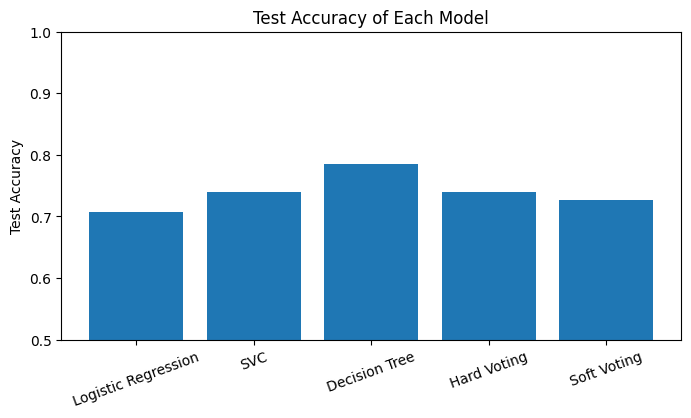

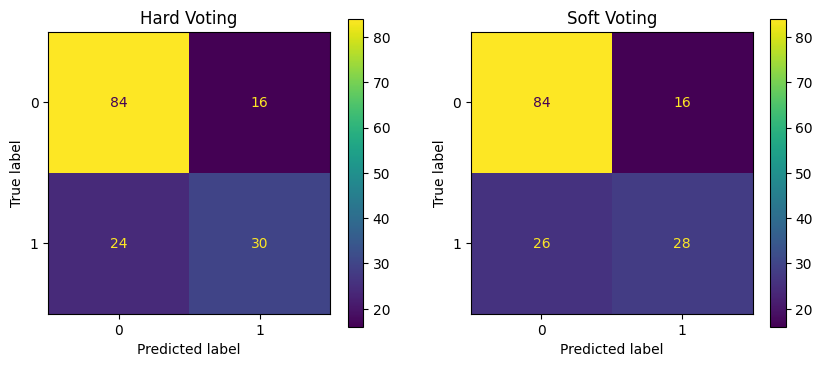

{'Logistic Regression': 0.7077922077922078, 'SVC': 0.7402597402597403, 'Decision Tree': 0.7857142857142857, 'Hard Voting': 0.7402597402597403, 'Soft Voting': 0.7272727272727273}


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def make_pipe(model):
    return Pipeline([("prep", preprocess), ("model", model)])

estimators = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("svc", SVC(kernel="rbf", probability=True, random_state=42)),
    ("tree", DecisionTreeClassifier(max_depth=4, random_state=42))]

pipes = {
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, random_state=42)),
    "SVC": make_pipe(SVC(kernel="rbf", probability=True, random_state=42)),
    "Decision Tree": make_pipe(DecisionTreeClassifier(max_depth=4, random_state=42)),
    "Hard Voting": make_pipe(VotingClassifier(estimators=estimators, voting="hard")),
    "Soft Voting": make_pipe(VotingClassifier(estimators=estimators, voting="soft"))}

accs = {}
preds = {}
for name, pipe in pipes.items():
    pipe.fit(X_train, y_train)
    preds[name] = pipe.predict(X_test)
    accs[name] = accuracy_score(y_test, preds[name])

for name in ["Hard Voting", "Soft Voting"]:
    print(name, "test accuracy:", round(accs[name], 4))
    print(classification_report(y_test, preds[name]))

plt.figure(figsize=(8, 4))
plt.bar(accs.keys(), accs.values())
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy of Each Model")
plt.xticks(rotation=20)
plt.ylim(0.5, 1.0)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["Hard Voting", "Soft Voting"]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], ax=ax)
    ax.set_title(name)
plt.show()

print(accs)

Task 6: Bagging Classifier with Out-of-Bag Evaluation. In this step I train a Bagging Classifier. The patients a tree never saw are called its out-of-bag patients, and I can use them as a free test, because every patient is left out by some of the trees.Then I grade the same bagging model on the real held out test set and compare the two numbers. I plot both accuracies side by side in one bar chart.

OOB score: 0.7557
Test accuracy: 0.7208
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       100
           1       0.62      0.52      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.67      0.68       154
weighted avg       0.71      0.72      0.71       154



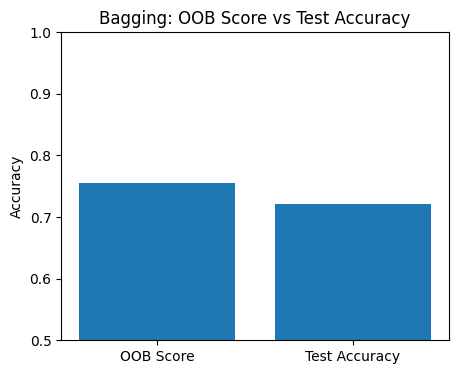

In [8]:
from sklearn.ensemble import BaggingClassifier

bag_pipe = make_pipe(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=42))
bag_pipe.fit(X_train, y_train)

oob = bag_pipe.named_steps["model"].oob_score_
bag_pred = bag_pipe.predict(X_test)
bag_test = accuracy_score(y_test, bag_pred)

print("OOB score:", round(oob, 4))
print("Test accuracy:", round(bag_test, 4))
print(classification_report(y_test, bag_pred))

plt.figure(figsize=(5, 4))
plt.bar(["OOB Score", "Test Accuracy"], [oob, bag_test])
plt.ylabel("Accuracy")
plt.title("Bagging: OOB Score vs Test Accuracy")
plt.ylim(0.5, 1.0)
plt.show()

Task 7: Random Forest Classifier. In this step I train a Random Forest with 100 trees. It works like bagging, with one extra twist. Each tree is trained on a random sample of patients, and at every split the tree is only allowed to look at a random handful of the features. That forces the trees to be different from each other, so when they vote together their mistakes cancel out more. I grade it on the test set with accuracy and the classification report. Then I look at feature importances, which score how much each feature helped the trees split patients into diabetic and non-diabetic groups. I plot them as a horizontal bar chart.

Random Forest test accuracy: 0.7727
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154

glucose                       0.272616
bmi                           0.163688
diabetes_pedigree_function    0.124927
age                           0.113057
insulin                       0.089395
blood_pressure                0.084337
pregnancies                   0.080793
skin_thickness                0.071187
dtype: float64


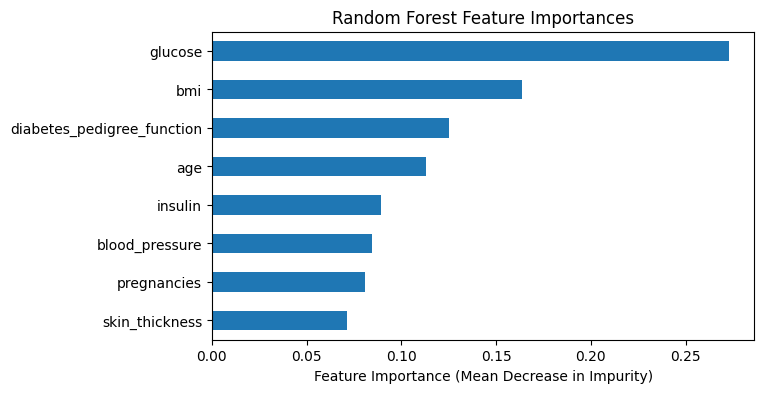

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = make_pipe(RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=42))
rf_pipe.fit(X_train, y_train)

rf_pred = rf_pipe.predict(X_test)
rf_test = accuracy_score(y_test, rf_pred)

print("Random Forest test accuracy:", round(rf_test, 4))
print(classification_report(y_test, rf_pred))

rf = rf_pipe.named_steps["model"]
imp = pd.Series(rf.feature_importances_, index=num_cols).sort_values()
print(imp.sort_values(ascending=False))

plt.figure(figsize=(7, 4))
imp.plot(kind="barh")
plt.xlabel("Feature Importance (Mean Decrease in Impurity)")
plt.title("Random Forest Feature Importances")
plt.show()

Task 8: AdaBoost Classifier. In this step I train an AdaBoost model. I build 100 stumps and, using staged_predict, I check the accuracy on both the training patients and the test patients after every stump is added. Then I plot both as lines. I also print the final training and test accuracy and the classification report.

Final train accuracy: 0.8143
Final test accuracy: 0.7597
Best test accuracy: 0.7662 at 21 stumps
              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154



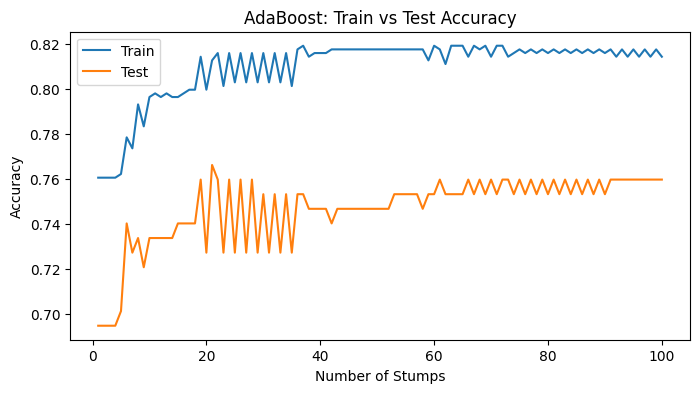

In [10]:
from sklearn.ensemble import AdaBoostClassifier

ada_pipe = make_pipe(AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42))
ada_pipe.fit(X_train, y_train)

ada = ada_pipe.named_steps["model"]
Xtr = ada_pipe.named_steps["prep"].transform(X_train)
Xte = ada_pipe.named_steps["prep"].transform(X_test)

train_curve = [accuracy_score(y_train, p) for p in ada.staged_predict(Xtr)]
test_curve = [accuracy_score(y_test, p) for p in ada.staged_predict(Xte)]

print("Final train accuracy:", round(train_curve[-1], 4))
print("Final test accuracy:", round(test_curve[-1], 4))
print("Best test accuracy:", round(max(test_curve), 4), "at", test_curve.index(max(test_curve)) + 1, "stumps")
print(classification_report(y_test, ada_pipe.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(range(1, 101), train_curve, label="Train")
plt.plot(range(1, 101), test_curve, label="Test")
plt.xlabel("Number of Stumps")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Train vs Test Accuracy")
plt.legend()
plt.show()